# Phase 3: Exploratory Data Analysis (EDA)

This notebook performs comprehensive exploratory data analysis on the cleaned dataset. We'll uncover customer behaviors, revenue patterns, product performance, and temporal trends.

**Goals:**
- Load cleaned dataset and verify structure
- Understand distribution of key variables
- Analyze product performance
- Geographic analysis
- Temporal trends
- Correlation analysis
- Generate professional visualizations for reports

**Tracking Milestone:**
✔ Load cleaned dataset
✔ Understand structure: shape, summary stats
✔ Univariate analysis (distributions)
✔ Bivariate analysis (relationships)
✔ Revenue analysis
✔ Country analysis
✔ Monthly trends
✔ Correlation analysis
✔ Save all charts to `reports/figures/`

In [1]:
# Cell 1: Imports & Load Clean Data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set style for better-looking plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Load cleaned data
df = pd.read_csv("../data/processed/online_retail_cleaned.csv")

print("✓ Cleaned dataset loaded successfully")
print(f"Shape: {df.shape}")
print(f"\nFirst 5 rows:")
df.head()

✓ Cleaned dataset loaded successfully
Shape: (5000, 9)

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Amount
0,INV004989,PROD0026,product prod0026,30,2011-04-16,17.859765,12050,United Kingdom,535.792956
1,INV003926,PROD0044,product prod0044,26,2011-11-13,11.229507,12487,Sweden,291.967174
2,INV001944,PROD0003,product prod0003,46,2011-08-25,29.482945,12070,Netherlands,1356.215475
3,INV008629,PROD0085,product prod0085,19,2011-07-07,17.730730,12479,Germany,336.883862
4,INV005391,PROD0089,product prod0089,21,2011-01-26,33.040955,12047,Netherlands,693.860065


In [2]:
# Cell 2: Basic Dataset Structure & Summary Statistics

print("=" * 80)
print("DATASET STRUCTURE & SUMMARY")
print("=" * 80)

print("\n📋 DATA TYPES:")
print(df.dtypes)

print("\n📊 DESCRIPTIVE STATISTICS:")
print(df.describe())

print("\n🔢 CATEGORICAL COLUMNS:")
print(f"Countries: {df['Country'].nunique()}")
print(f"Products: {df['StockCode'].nunique()}")
print(f"Customers: {df['CustomerID'].nunique()}")
print(f"Invoices: {df['InvoiceNo'].nunique()}")

DATASET STRUCTURE & SUMMARY

📋 DATA TYPES:
InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID       int64
Country         object
Amount         float64
dtype: object

📊 DESCRIPTIVE STATISTICS:
          Quantity    UnitPrice    CustomerID       Amount
count  5000.000000  5000.000000   5000.000000  5000.000000
mean     24.731200    25.592517  12247.881000   631.352361
std      14.228262    14.229608    143.625272   543.986763
min       1.000000     0.512496  12000.000000     1.025067
25%      13.000000    13.387068  12122.000000   184.291177
50%      24.000000    25.827846  12246.000000   483.563289
75%      37.000000    37.885514  12372.250000   955.017774
max      49.000000    49.996279  12499.000000  2392.796097

🔢 CATEGORICAL COLUMNS:
Countries: 6
Products: 100
Customers: 500
Invoices: 3922



QUANTITY ANALYSIS

Quantity Statistics:
  • Min: 1
  • Max: 49
  • Mean: 24.73
  • Median: 24.00
  • Std Dev: 14.23


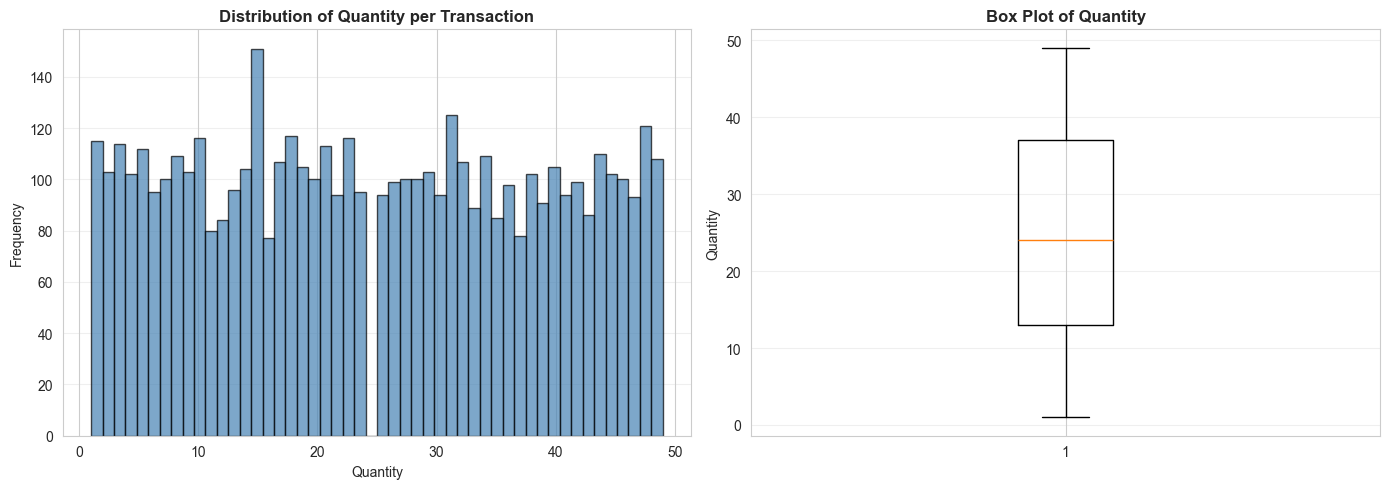


✓ Quantity distribution saved


In [3]:
# Cell 3: Distribution of Quantity

print("\n" + "=" * 80)
print("QUANTITY ANALYSIS")
print("=" * 80)

print(f"\nQuantity Statistics:")
print(f"  • Min: {df['Quantity'].min()}")
print(f"  • Max: {df['Quantity'].max()}")
print(f"  • Mean: {df['Quantity'].mean():.2f}")
print(f"  • Median: {df['Quantity'].median():.2f}")
print(f"  • Std Dev: {df['Quantity'].std():.2f}")

# Visualize quantity distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(df['Quantity'], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_title('Distribution of Quantity per Transaction', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Quantity')
axes[0].set_ylabel('Frequency')
axes[0].grid(axis='y', alpha=0.3)

# Box plot
axes[1].boxplot(df['Quantity'], vert=True)
axes[1].set_title('Box Plot of Quantity', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Quantity')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig("../reports/figures/quantity_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Quantity distribution saved")


UNIT PRICE ANALYSIS

Unit Price Statistics:
  • Min: £0.51
  • Max: £50.00
  • Mean: £25.59
  • Median: £25.83
  • Std Dev: £14.23


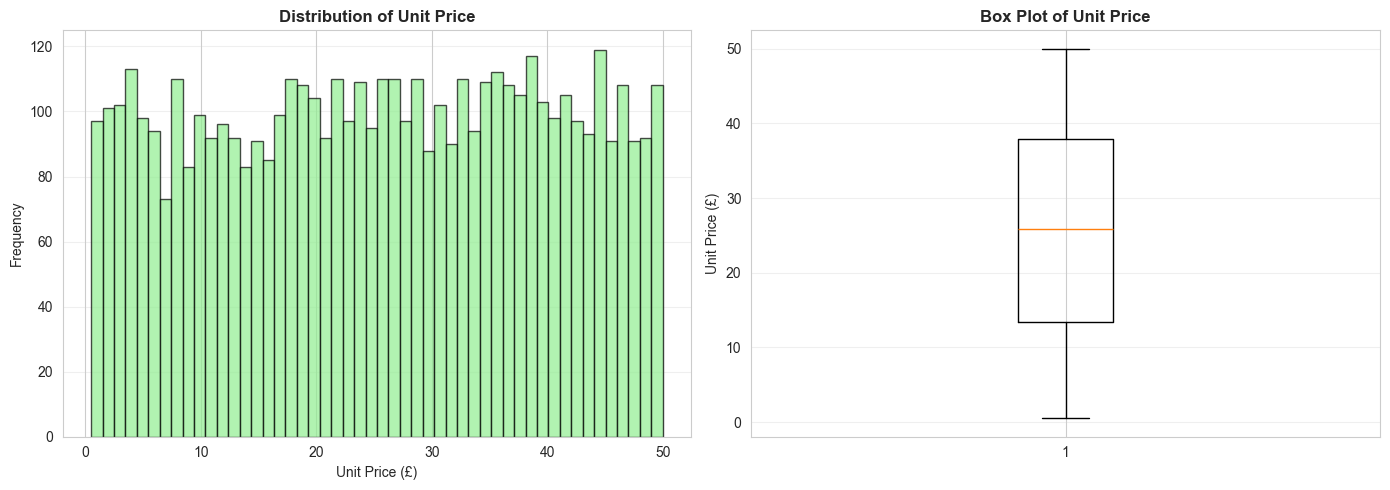


✓ Unit price distribution saved


In [4]:
# Cell 4: Distribution of Unit Price

print("\n" + "=" * 80)
print("UNIT PRICE ANALYSIS")
print("=" * 80)

print(f"\nUnit Price Statistics:")
print(f"  • Min: £{df['UnitPrice'].min():.2f}")
print(f"  • Max: £{df['UnitPrice'].max():.2f}")
print(f"  • Mean: £{df['UnitPrice'].mean():.2f}")
print(f"  • Median: £{df['UnitPrice'].median():.2f}")
print(f"  • Std Dev: £{df['UnitPrice'].std():.2f}")

# Visualize unit price distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(df['UnitPrice'], bins=50, color='lightgreen', edgecolor='black', alpha=0.7)
axes[0].set_title('Distribution of Unit Price', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Unit Price (£)')
axes[0].set_ylabel('Frequency')
axes[0].grid(axis='y', alpha=0.3)

# Box plot
axes[1].boxplot(df['UnitPrice'], vert=True)
axes[1].set_title('Box Plot of Unit Price', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Unit Price (£)')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig("../reports/figures/unitprice_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Unit price distribution saved")


TRANSACTION AMOUNT ANALYSIS

Amount Statistics:
  • Min: £1.03
  • Max: £2392.80
  • Mean: £631.35
  • Median: £483.56
  • Std Dev: £543.99
  • Total Revenue: £3,156,761.80


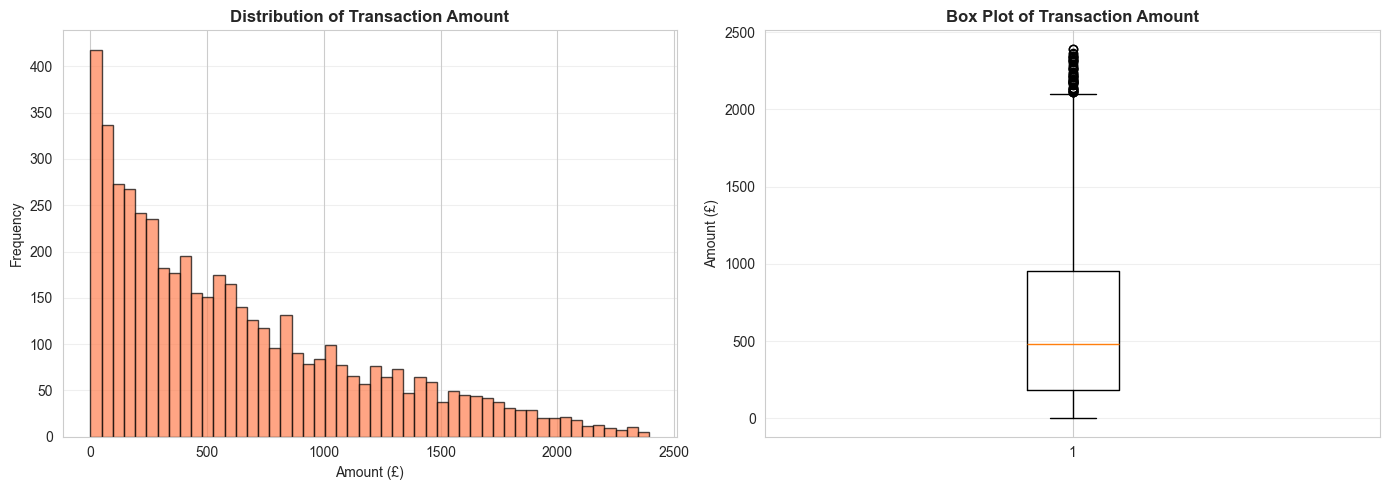


✓ Transaction amount distribution saved


In [5]:
# Cell 5: Distribution of Transaction Amount

print("\n" + "=" * 80)
print("TRANSACTION AMOUNT ANALYSIS")
print("=" * 80)

print(f"\nAmount Statistics:")
print(f"  • Min: £{df['Amount'].min():.2f}")
print(f"  • Max: £{df['Amount'].max():.2f}")
print(f"  • Mean: £{df['Amount'].mean():.2f}")
print(f"  • Median: £{df['Amount'].median():.2f}")
print(f"  • Std Dev: £{df['Amount'].std():.2f}")
print(f"  • Total Revenue: £{df['Amount'].sum():,.2f}")

# Visualize amount distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(df['Amount'], bins=50, color='coral', edgecolor='black', alpha=0.7)
axes[0].set_title('Distribution of Transaction Amount', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Amount (£)')
axes[0].set_ylabel('Frequency')
axes[0].grid(axis='y', alpha=0.3)

# Box plot
axes[1].boxplot(df['Amount'], vert=True)
axes[1].set_title('Box Plot of Transaction Amount', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Amount (£)')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig("../reports/figures/amount_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Transaction amount distribution saved")


TOP PRODUCTS ANALYSIS

Top 10 Products by Revenue:
                Revenue  Quantity_Sold
StockCode                             
PROD0047   47860.351996           1795
PROD0046   47254.836872           1696
PROD0079   47074.004614           1736
PROD0056   45173.314894           1563
PROD0053   42753.982807           1622
PROD0089   42361.716303           1482
PROD0054   41501.651585           1293
PROD0044   40069.632579           1510
PROD0077   39370.821080           1584
PROD0002   39002.733404           1497


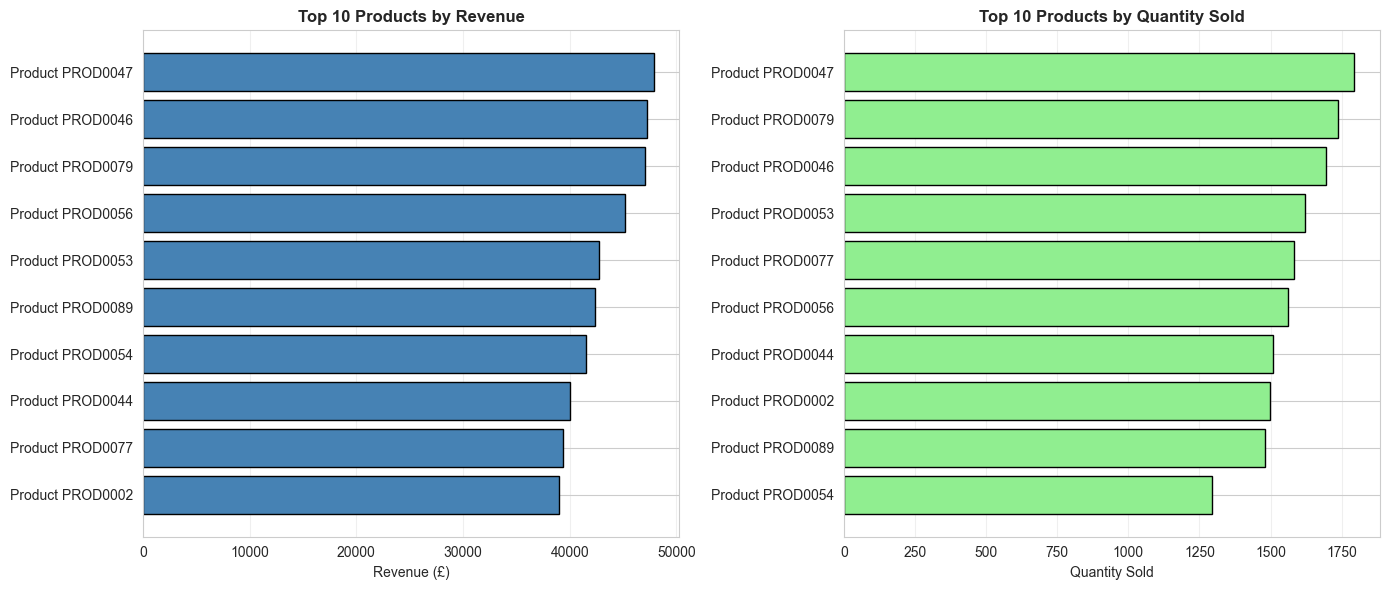


✓ Top products visualization saved


In [6]:
# Cell 6: Top 10 Products by Revenue

print("\n" + "=" * 80)
print("TOP PRODUCTS ANALYSIS")
print("=" * 80)

# Calculate revenue per product
product_revenue = df.groupby('StockCode').agg({
    'Amount': 'sum',
    'Quantity': 'sum'
}).sort_values('Amount', ascending=False).head(10)

product_revenue.columns = ['Revenue', 'Quantity_Sold']

print("\nTop 10 Products by Revenue:")
print(product_revenue)

# Visualize top products
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Revenue bar chart
top_products_revenue = product_revenue['Revenue'].sort_values(ascending=True).tail(10)
axes[0].barh(range(len(top_products_revenue)), top_products_revenue.values, color='steelblue', edgecolor='black')
axes[0].set_yticks(range(len(top_products_revenue)))
axes[0].set_yticklabels([f'Product {i}' for i in top_products_revenue.index])
axes[0].set_title('Top 10 Products by Revenue', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Revenue (£)')
axes[0].grid(axis='x', alpha=0.3)

# Quantity sold bar chart
top_products_qty = product_revenue['Quantity_Sold'].sort_values(ascending=True).tail(10)
axes[1].barh(range(len(top_products_qty)), top_products_qty.values, color='lightgreen', edgecolor='black')
axes[1].set_yticks(range(len(top_products_qty)))
axes[1].set_yticklabels([f'Product {i}' for i in top_products_qty.index])
axes[1].set_title('Top 10 Products by Quantity Sold', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Quantity Sold')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig("../reports/figures/top_products_revenue.png", dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Top products visualization saved")


COUNTRY ANALYSIS

Top 10 Countries by Revenue:
                      Revenue  Invoices  Customers
Country                                           
USA             585316.718374       862        423
Netherlands     532985.020591       843        421
United Kingdom  532641.873885       788        404
Sweden          512792.573275       782        404
Germany         510392.158751       761        396
France          482633.458084       763        394


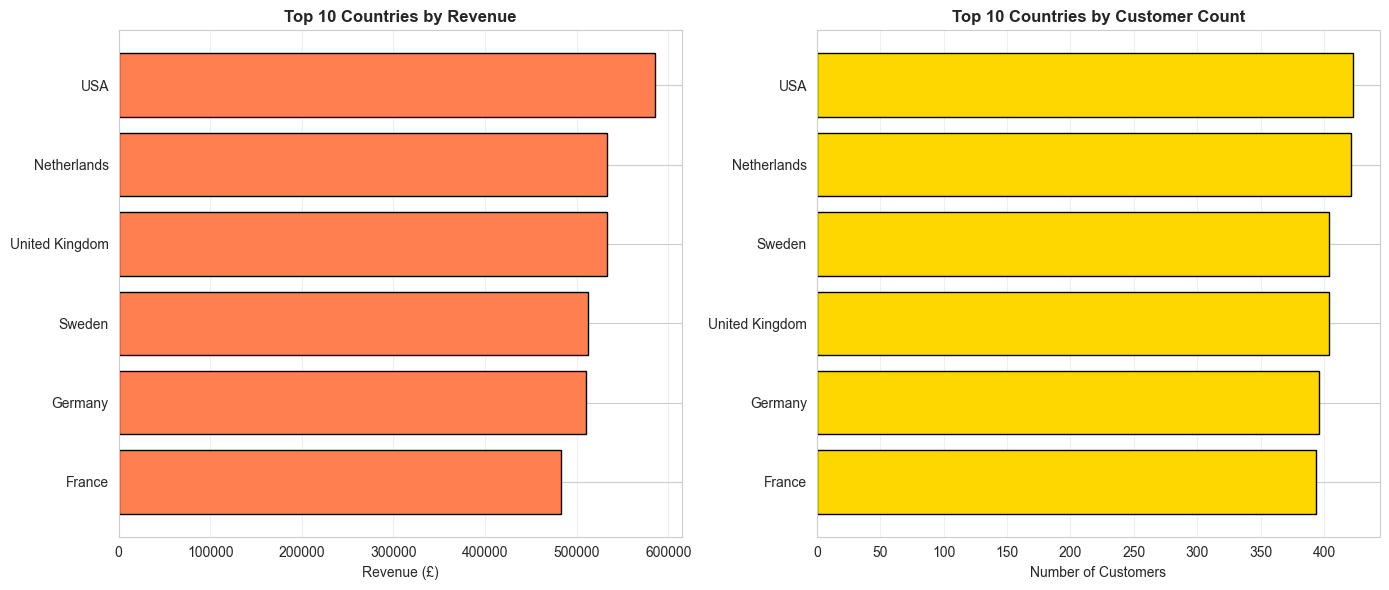


✓ Country analysis visualization saved


In [7]:
# Cell 7: Revenue by Country

print("\n" + "=" * 80)
print("COUNTRY ANALYSIS")
print("=" * 80)

# Calculate revenue per country
country_revenue = df.groupby('Country').agg({
    'Amount': 'sum',
    'InvoiceNo': 'nunique',
    'CustomerID': 'nunique'
}).sort_values('Amount', ascending=False)

country_revenue.columns = ['Revenue', 'Invoices', 'Customers']

print("\nTop 10 Countries by Revenue:")
print(country_revenue.head(10))

# Visualize top countries
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Revenue bar chart
top_countries_revenue = country_revenue['Revenue'].head(10).sort_values(ascending=True)
axes[0].barh(range(len(top_countries_revenue)), top_countries_revenue.values, color='coral', edgecolor='black')
axes[0].set_yticks(range(len(top_countries_revenue)))
axes[0].set_yticklabels(top_countries_revenue.index)
axes[0].set_title('Top 10 Countries by Revenue', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Revenue (£)')
axes[0].grid(axis='x', alpha=0.3)

# Customer count bar chart
top_countries_customers = country_revenue['Customers'].head(10).sort_values(ascending=True)
axes[1].barh(range(len(top_countries_customers)), top_countries_customers.values, color='gold', edgecolor='black')
axes[1].set_yticks(range(len(top_countries_customers)))
axes[1].set_yticklabels(top_countries_customers.index)
axes[1].set_title('Top 10 Countries by Customer Count', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Customers')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig("../reports/figures/top_countries_revenue.png", dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Country analysis visualization saved")


TEMPORAL ANALYSIS - MONTHLY TRENDS

Monthly Statistics (First 10 months):
           Total_Revenue  Avg_Amount  Transactions  Quantity  Customers
YearMonth                                                              
2010-12        286873.95      623.64           460     10972        302
2011-01        286520.75      674.17           425     11022        291
2011-02        223680.98      602.91           371      8757        256
2011-03        266337.11      640.23           416     10342        290
2011-04        266858.37      617.73           432     10555        280
2011-05        248925.84      633.40           393      9862        270
2011-06        253394.41      635.07           399     10005        276
2011-07        270143.29      600.32           450     10922        296
2011-08        272802.07      651.08           419     10553        288
2011-09        278926.02      653.22           427     10710        290


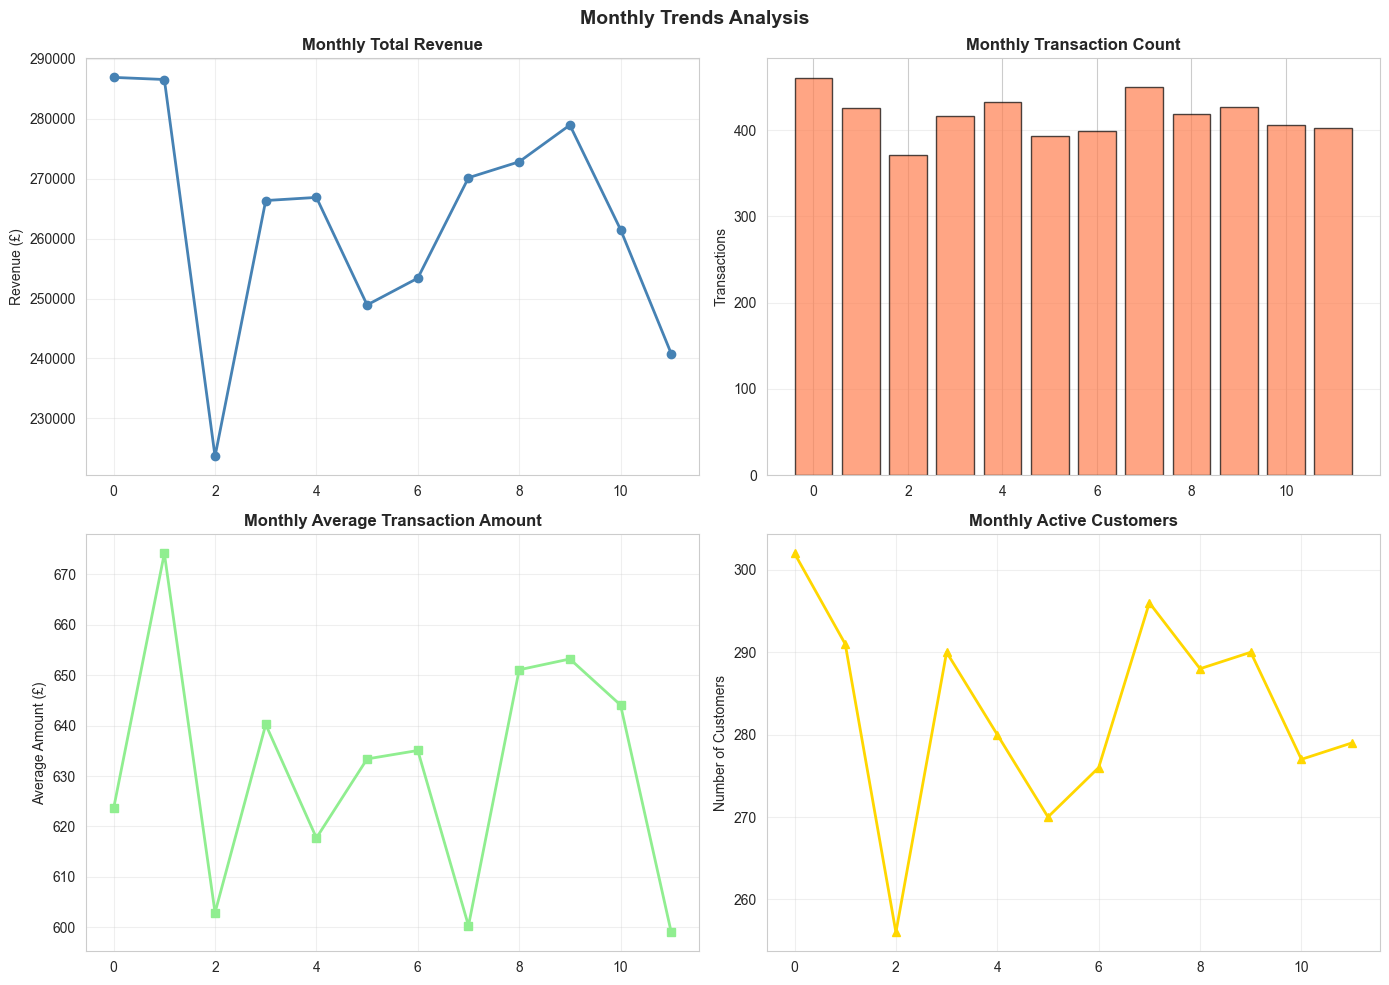


✓ Monthly trends visualization saved


In [8]:
# Cell 8: Monthly Revenue Trends

print("\n" + "=" * 80)
print("TEMPORAL ANALYSIS - MONTHLY TRENDS")
print("=" * 80)

# Convert to datetime if not already
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')

# Calculate monthly metrics
monthly_stats = df.groupby('YearMonth').agg({
    'Amount': ['sum', 'mean', 'count'],
    'Quantity': 'sum',
    'CustomerID': 'nunique'
}).round(2)

monthly_stats.columns = ['Total_Revenue', 'Avg_Amount', 'Transactions', 'Quantity', 'Customers']

print("\nMonthly Statistics (First 10 months):")
print(monthly_stats.head(10))

# Visualize monthly trends
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Monthly Trends Analysis', fontsize=14, fontweight='bold')

# Total Revenue
monthly_revenue = df.groupby('YearMonth')['Amount'].sum()
axes[0, 0].plot(range(len(monthly_revenue)), monthly_revenue.values, marker='o', linewidth=2, color='steelblue')
axes[0, 0].set_title('Monthly Total Revenue', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Revenue (£)')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].set_xticks(range(0, len(monthly_revenue), 2))

# Transaction Count
monthly_trans = df.groupby('YearMonth').size()
axes[0, 1].bar(range(len(monthly_trans)), monthly_trans.values, color='coral', edgecolor='black', alpha=0.7)
axes[0, 1].set_title('Monthly Transaction Count', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Transactions')
axes[0, 1].grid(True, alpha=0.3, axis='y')
axes[0, 1].set_xticks(range(0, len(monthly_trans), 2))

# Average Amount
monthly_avg = df.groupby('YearMonth')['Amount'].mean()
axes[1, 0].plot(range(len(monthly_avg)), monthly_avg.values, marker='s', linewidth=2, color='lightgreen')
axes[1, 0].set_title('Monthly Average Transaction Amount', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Average Amount (£)')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].set_xticks(range(0, len(monthly_avg), 2))

# Customer Count
monthly_customers = df.groupby('YearMonth')['CustomerID'].nunique()
axes[1, 1].plot(range(len(monthly_customers)), monthly_customers.values, marker='^', linewidth=2, color='gold')
axes[1, 1].set_title('Monthly Active Customers', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Number of Customers')
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].set_xticks(range(0, len(monthly_customers), 2))

plt.tight_layout()
plt.savefig("../reports/figures/monthly_trends.png", dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Monthly trends visualization saved")


BIVARIATE ANALYSIS - QUANTITY VS PRICE

Correlation between Quantity and UnitPrice: -0.0078


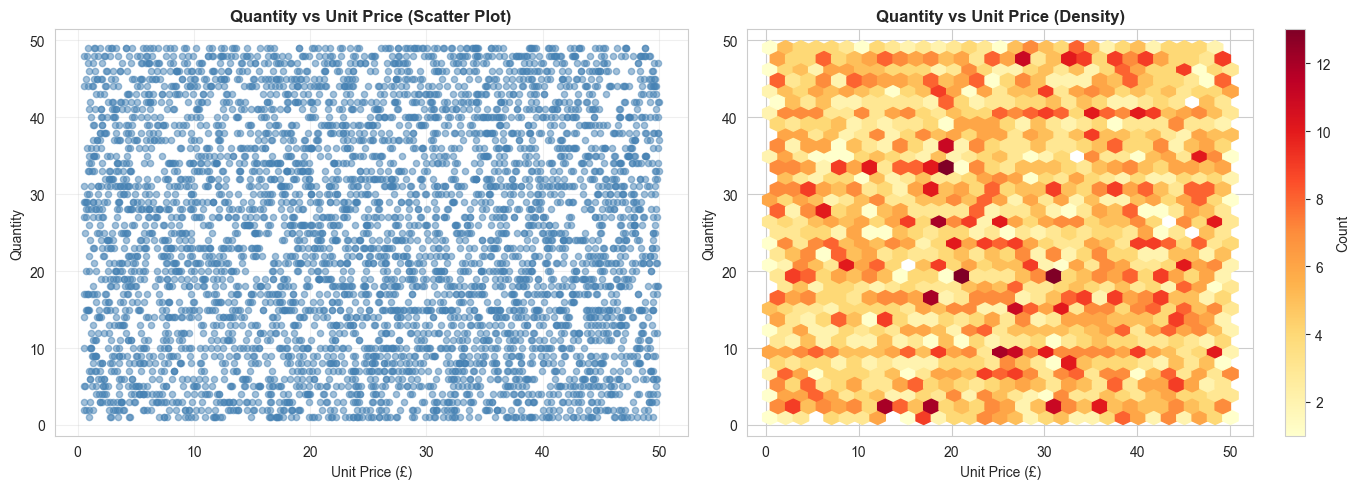


✓ Quantity vs Price visualization saved


In [9]:
# Cell 9: Quantity vs Price Relationship

print("\n" + "=" * 80)
print("BIVARIATE ANALYSIS - QUANTITY VS PRICE")
print("=" * 80)

# Calculate correlation
correlation = df['Quantity'].corr(df['UnitPrice'])
print(f"\nCorrelation between Quantity and UnitPrice: {correlation:.4f}")

# Visualize relationship
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot
axes[0].scatter(df['UnitPrice'], df['Quantity'], alpha=0.5, s=20, color='steelblue')
axes[0].set_title('Quantity vs Unit Price (Scatter Plot)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Unit Price (£)')
axes[0].set_ylabel('Quantity')
axes[0].grid(True, alpha=0.3)

# Hexbin plot for density
hexbin = axes[1].hexbin(df['UnitPrice'], df['Quantity'], gridsize=30, cmap='YlOrRd', mincnt=1)
axes[1].set_title('Quantity vs Unit Price (Density)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Unit Price (£)')
axes[1].set_ylabel('Quantity')
plt.colorbar(hexbin, ax=axes[1], label='Count')

plt.tight_layout()
plt.savefig("../reports/figures/quantity_vs_unitprice.png", dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Quantity vs Price visualization saved")


CORRELATION MATRIX ANALYSIS

Correlation Matrix:
           Quantity  UnitPrice    Amount
Quantity   1.000000  -0.007812  0.665105
UnitPrice -0.007812   1.000000  0.643054
Amount     0.665105   0.643054  1.000000


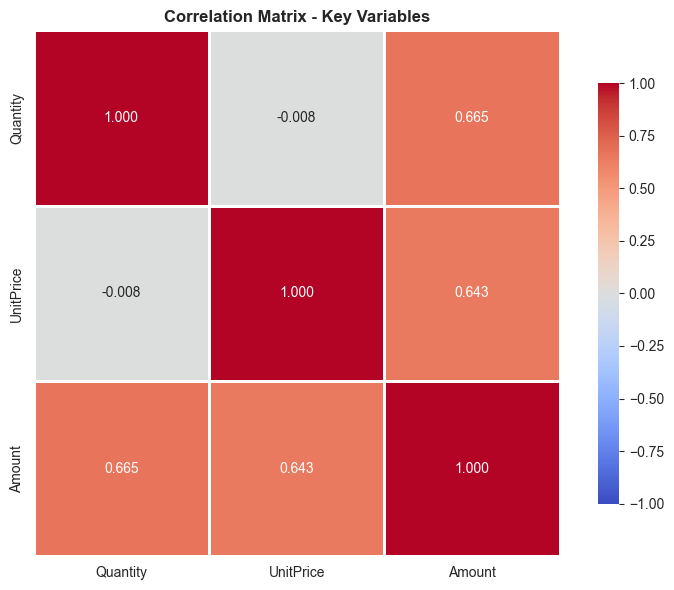


✓ Correlation heatmap saved


In [10]:
# Cell 10: Correlation Analysis

print("\n" + "=" * 80)
print("CORRELATION MATRIX ANALYSIS")
print("=" * 80)

# Calculate correlation matrix for numeric columns
numeric_cols = ['Quantity', 'UnitPrice', 'Amount']
correlation_matrix = df[numeric_cols].corr()

print("\nCorrelation Matrix:")
print(correlation_matrix)

# Visualize correlation matrix
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, fmt='.3f', cmap='coolwarm', center=0,
            square=True, linewidths=2, cbar_kws={"shrink": 0.8}, ax=ax, vmin=-1, vmax=1)
ax.set_title('Correlation Matrix - Key Variables', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig("../reports/figures/correlation_heatmap.png", dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Correlation heatmap saved")

In [11]:
# Cell 11: EDA Summary Report

print("\n" + "=" * 80)
print("PHASE 3 - EXPLORATORY DATA ANALYSIS SUMMARY")
print("=" * 80)

print(f"""
✅ EDA Milestone Completed

Dataset Overview:
  • Total Transactions: {len(df):,}
  • Unique Customers: {df['CustomerID'].nunique():,}
  • Unique Products: {df['StockCode'].nunique():,}
  • Countries: {df['Country'].nunique():,}
  • Date Range: {df['InvoiceDate'].min().date()} to {df['InvoiceDate'].max().date()}

Financial Metrics:
  • Total Revenue: £{df['Amount'].sum():,.2f}
  • Average Transaction: £{df['Amount'].mean():.2f}
  • Median Transaction: £{df['Amount'].median():.2f}
  • Max Transaction: £{df['Amount'].max():.2f}

Customer Insights:
  • Avg Purchases per Customer: {df.groupby('CustomerID')['InvoiceNo'].nunique().mean():.1f}
  • Avg Spend per Customer: £{df.groupby('CustomerID')['Amount'].sum().mean():.2f}

Product Insights:
  • Products in Dataset: {df['StockCode'].nunique():,}
  • Avg Quantity per Transaction: {df['Quantity'].mean():.1f}
  • Avg Price per Item: £{df['UnitPrice'].mean():.2f}

Top Market:
  • {df['Country'].value_counts().index[0]}: {df[df['Country']==df['Country'].value_counts().index[0]]['Amount'].sum():,.2f}

Visualizations Generated:
  ✓ quantity_distribution.png
  ✓ unitprice_distribution.png
  ✓ amount_distribution.png
  ✓ top_products_revenue.png
  ✓ top_countries_revenue.png
  ✓ monthly_trends.png
  ✓ quantity_vs_unitprice.png
  ✓ correlation_heatmap.png

All figures saved to: reports/figures/

✓ EDA Complete - Data is fully understood and ready for feature engineering
""")

print("=" * 80)
print("Ready for Phase 4: Feature Engineering (RFM Analysis)")
print("=" * 80)


PHASE 3 - EXPLORATORY DATA ANALYSIS SUMMARY

✅ EDA Milestone Completed

Dataset Overview:
  • Total Transactions: 5,000
  • Unique Customers: 500
  • Unique Products: 100
  • Countries: 6
  • Date Range: 2010-12-01 to 2011-11-30

Financial Metrics:
  • Total Revenue: £3,156,761.80
  • Average Transaction: £631.35
  • Median Transaction: £483.56
  • Max Transaction: £2392.80

Customer Insights:
  • Avg Purchases per Customer: 10.0
  • Avg Spend per Customer: £6313.52

Product Insights:
  • Products in Dataset: 100
  • Avg Quantity per Transaction: 24.7
  • Avg Price per Item: £25.59

Top Market:
  • USA: 585,316.72

Visualizations Generated:
  ✓ quantity_distribution.png
  ✓ unitprice_distribution.png
  ✓ amount_distribution.png
  ✓ top_products_revenue.png
  ✓ top_countries_revenue.png
  ✓ monthly_trends.png
  ✓ quantity_vs_unitprice.png
  ✓ correlation_heatmap.png

All figures saved to: reports/figures/

✓ EDA Complete - Data is fully understood and ready for feature engineering

Rea

In [12]:
# Cell 12: Save Key Statistics to CSV (Optional)

# Save summary statistics for reference
summary_dict = {
    'Metric': [
        'Total Transactions',
        'Unique Customers',
        'Unique Products',
        'Countries',
        'Total Revenue',
        'Avg Transaction',
        'Median Transaction',
        'Date Range (Start)',
        'Date Range (End)'
    ],
    'Value': [
        f"{len(df):,}",
        f"{df['CustomerID'].nunique():,}",
        f"{df['StockCode'].nunique():,}",
        f"{df['Country'].nunique():,}",
        f"£{df['Amount'].sum():,.2f}",
        f"£{df['Amount'].mean():.2f}",
        f"£{df['Amount'].median():.2f}",
        str(df['InvoiceDate'].min().date()),
        str(df['InvoiceDate'].max().date())
    ]
}

summary_df = pd.DataFrame(summary_dict)
summary_df.to_csv('../reports/eda_summary_statistics.csv', index=False)

print("✓ EDA Summary statistics saved to reports/eda_summary_statistics.csv")
print("\n" + "=" * 80)
print("✓ PHASE 3 COMPLETE - Ready for Phase 4: Feature Engineering")
print("=" * 80)

✓ EDA Summary statistics saved to reports/eda_summary_statistics.csv

✓ PHASE 3 COMPLETE - Ready for Phase 4: Feature Engineering
